<a href="https://colab.research.google.com/github/heewon04/2025_DM/blob/main/%EC%84%A0%EB%8C%807%EC%A3%BC%EC%B0%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

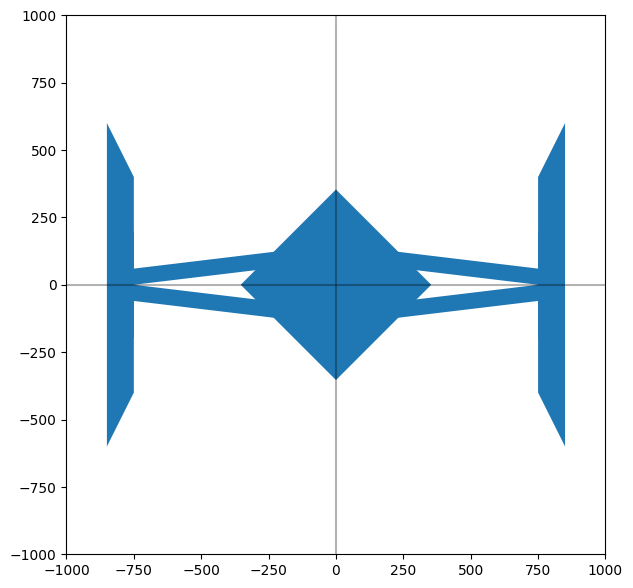

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon


INF = 1000       # 그림판 크기
LEN = 100        # 처음 사각형의 크기


# ============================================================
# 변환 함수
# ============================================================

# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
    # 1. 동차좌표계 변환
    hp = np.array([p[0], p[1], 1.0])

    # 2. 이동 변환 행렬 생성
    m = np.array([
        [1.0, 0.0, dx],
        [0.0, 1.0, dy],
        [0.0, 0.0, 1.0]
    ])

    # 3. 행렬과 벡터의 곱
    q = np.dot(m, hp)

    # 2차원 좌표계로 변환
    q = np.array([q[0], q[1]])
    return q


def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [np.cos(theta), -np.sin(theta), 0.0],
        [np.sin(theta),  np.cos(theta), 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [sx, 0.0, 0.0],
        [0.0, sy, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, sx, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, 0.0],
        [sy, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


# x축 대칭
def reflect_x(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


# y축 대칭
def reflect_y(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [-1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


# 원점 대칭
def reflect_origin(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [-1.0, 0.0, 0.0],
        [0.0, -1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


# 직선 y=x 대칭
def reflect_y_eq_x(p):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [0.0, 1.0, 0.0],
        [1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q


# ============================================================
# 그리기 함수
# ============================================================

def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')


def draw_rectangle(ax, p1, p2, p3, p4):
    my_polygon = Polygon([p1, p2, p3, p4])
    ax.add_patch(my_polygon)


def draw_cockpit(ax, p1, p2, p3, p4):
    # 1. 사각형을 원점으로 이동 변환
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 크기 변환: S(5, 5)
    s = 5
    q1 = scale(q1, s, s)
    q2 = scale(q2, s, s)
    q3 = scale(q3, s, s)
    q4 = scale(q4, s, s)

    # 3. 회전 변환: R(pi/4)
    q1 = rotate(q1, np.pi/4)
    q2 = rotate(q2, np.pi/4)
    q3 = rotate(q3, np.pi/4)
    q4 = rotate(q4, np.pi/4)

    draw_rectangle(ax, q1, q2, q3, q4)


def draw_left_arm(ax, p1, p2, p3, p4):
    # 1. 크기 변환
    q1 = scale(p1, 5.5, 0.6)
    q2 = scale(p2, 5.5, 0.6)
    q3 = scale(p3, 5.5, 0.6)
    q4 = scale(p4, 5.5, 0.6)

    # 2. y축 방향 밀림
    q1 = shear_y(q1, 0.12)
    q2 = shear_y(q2, 0.12)
    q3 = shear_y(q3, 0.12)
    q4 = shear_y(q4, 0.12)

    # 3. 왼쪽으로 이동
    q1 = translate(q1, -750, 0)
    q2 = translate(q2, -750, 0)
    q3 = translate(q3, -750, 0)
    q4 = translate(q4, -750, 0)

    # 왼쪽 날개축 윗부분
    draw_rectangle(ax, q1, q2, q3, q4)

    # x축 대칭으로 아랫부분 생성
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    draw_rectangle(ax, q1, q2, q3, q4)


def draw_left_wing(ax, p1, p2, p3, p4):
    # 1. 크기 변환
    q1 = scale(p1, 1, 6)
    q2 = scale(p2, 1, 6)
    q3 = scale(p3, 1, 6)
    q4 = scale(p4, 1, 6)

    # 2. y축 방향 밀림
    q1 = shear_y(q1, -2)
    q2 = shear_y(q2, -2)
    q3 = shear_y(q3, -2)
    q4 = shear_y(q4, -2)

    # 3. 왼쪽으로 이동
    q1 = translate(q1, -850, 0)
    q2 = translate(q2, -850, 0)
    q3 = translate(q3, -850, 0)
    q4 = translate(q4, -850, 0)

    # 왼쪽 날개 윗부분
    draw_rectangle(ax, q1, q2, q3, q4)

    # x축 대칭으로 아랫부분 생성
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    draw_rectangle(ax, q1, q2, q3, q4)


def draw_right_arm(ax, p1, p2, p3, p4):
    # 왼쪽 날개축을 만드는 것과 같은 변환
    q1 = scale(p1, 5.5, 0.6)
    q2 = scale(p2, 5.5, 0.6)
    q3 = scale(p3, 5.5, 0.6)
    q4 = scale(p4, 5.5, 0.6)

    q1 = shear_y(q1, 0.12)
    q2 = shear_y(q2, 0.12)
    q3 = shear_y(q3, 0.12)
    q4 = shear_y(q4, 0.12)

    q1 = translate(q1, -750, 0)
    q2 = translate(q2, -750, 0)
    q3 = translate(q3, -750, 0)
    q4 = translate(q4, -750, 0)

    # y축 대칭으로 오른쪽 날개축 생성
    q1 = reflect_y(q1)
    q2 = reflect_y(q2)
    q3 = reflect_y(q3)
    q4 = reflect_y(q4)

    draw_rectangle(ax, q1, q2, q3, q4)

    # x축 대칭으로 아랫부분 생성
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    draw_rectangle(ax, q1, q2, q3, q4)


def draw_right_wing(ax, p1, p2, p3, p4):
    # 왼쪽 날개를 만드는 것과 같은 변환
    q1 = scale(p1, 1, 6)
    q2 = scale(p2, 1, 6)
    q3 = scale(p3, 1, 6)
    q4 = scale(p4, 1, 6)

    q1 = shear_y(q1, -2)
    q2 = shear_y(q2, -2)
    q3 = shear_y(q3, -2)
    q4 = shear_y(q4, -2)

    q1 = translate(q1, -850, 0)
    q2 = translate(q2, -850, 0)
    q3 = translate(q3, -850, 0)
    q4 = translate(q4, -850, 0)

    # y축 대칭으로 오른쪽 날개 생성
    q1 = reflect_y(q1)
    q2 = reflect_y(q2)
    q3 = reflect_y(q3)
    q4 = reflect_y(q4)

    draw_rectangle(ax, q1, q2, q3, q4)

    # x축 대칭으로 아랫부분 생성
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    draw_rectangle(ax, q1, q2, q3, q4)


def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    # 1. 중앙 조종석 그리기
    draw_cockpit(ax, p1, p2, p3, p4)

    # 2. 왼쪽 날개축 그리기
    draw_left_arm(ax, p1, p2, p3, p4)

    # 3. 왼쪽 날개 그리기
    draw_left_wing(ax, p1, p2, p3, p4)

    # 4. 오른쪽 날개축 그리기
    draw_right_arm(ax, p1, p2, p3, p4)

    # 5. 오른쪽 날개 그리기
    draw_right_wing(ax, p1, p2, p3, p4)


# ============================================================
# 실행
# ============================================================

# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7, 7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()